# Phase 2: Modeling, Two-Tier Routing Ablation & End-to-End Evaluation

**Project:** LitScope-Lite — Evidence-Based Verification of Scientific Claims Using NLP  
**Dataset:** AllenAI SciFact Development Split (`claims_dev.jsonl`, `corpus.jsonl`)

This notebook evaluates the complete 4-module verification pipeline implemented under `src/`:
1. **Module 1 (`src/segmentation.py`):** Rule-based scientific claim segmentation.
2. **Module 2 (`src/retrieval.py`):** Hybrid lexical (TF-IDF) + dense (`all-MiniLM-L6-v2`) evidence retrieval.
3. **Module 3 (`src/rationale_selection.py`):** Sentence-level cosine similarity rationale extraction (threshold = 0.40, top-3).
4. **Module 4 (`src/stance.py`):** Zero-shot NLI stance classification with two-tier confidence routing (`nli-deberta-v3-xsmall` -> `nli-deberta-v3-base`).

All metrics and tables below are loaded from `outputs/evaluation/` generated by `python -m src.evaluate_phase2`, and all figures are exported to `images/`.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path.cwd()
EVAL_DIR = ROOT / "outputs" / "evaluation"
IMG_DIR = ROOT / "images"
IMG_DIR.mkdir(parents=True, exist_ok=True)

with open(EVAL_DIR / "phase2_evaluation_summary.json", "r", encoding="utf-8") as f:
    summary = json.load(f)

stance_df = pd.read_csv(EVAL_DIR / "stance_oracle_predictions.csv")
sweep_df = pd.read_csv(EVAL_DIR / "routing_threshold_sweep.csv")
e2e_df = pd.read_csv(EVAL_DIR / "end_to_end_sample_predictions.csv")
consistency_df = pd.read_csv(EVAL_DIR / "consistency_check.csv")

print(f"Loaded evaluation artifacts from: {EVAL_DIR}")
print(f"Oracle stance pairs: {len(stance_df)} | E2E sample claims: {len(e2e_df)} | Consistency cases: {len(consistency_df)}")


Loaded evaluation artifacts from: D:\DS_Projects\LitScope-Lite\outputs\evaluation
Oracle stance pairs: 338 | E2E sample claims: 60 | Consistency cases: 5


## 1. Module 2: Hybrid Evidence Retrieval Performance

We evaluate the 50/50 TF-IDF + `all-MiniLM-L6-v2` hybrid retriever across all **188 gold-annotated claims** in `claims_dev.jsonl` against the full 5,183-abstract SciFact corpus.


MRR@10: 0.7943 | Total Dev Claims with Gold Evidence: 188 | Runtime: 11.45s


,K,Recall@K,Precision@K
0,1,0.6844,0.7074
1,3,0.8326,0.2926
2,5,0.8956,0.1904
3,10,0.9638,0.1053


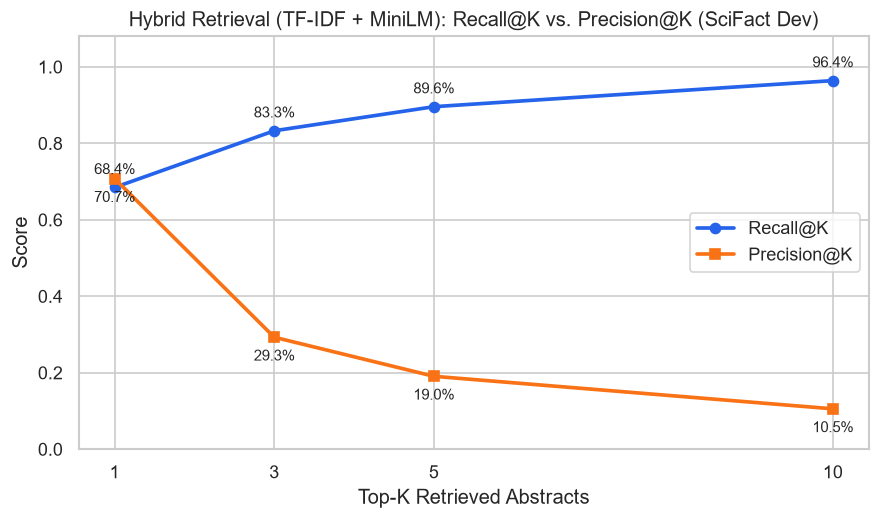

In [2]:
ret = summary["retrieval"]
ret_rows = [
    {"K": int(k), "Recall@K": v["recall"], "Precision@K": v["precision"]}
    for k, v in ret["metrics_by_k"].items()
]
ret_df = pd.DataFrame(ret_rows).sort_values("K")
print(f"MRR@10: {ret['mrr_at_10']:.4f} | Total Dev Claims with Gold Evidence: {ret['num_dev_claims_with_gold_evidence']} | Runtime: {ret['elapsed_seconds']}s")
display(ret_df)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(ret_df["K"], ret_df["Recall@K"], marker="o", linewidth=2.2, label="Recall@K", color="#2563eb")
ax.plot(ret_df["K"], ret_df["Precision@K"], marker="s", linewidth=2.2, label="Precision@K", color="#f97316")
for _, row in ret_df.iterrows():
    ax.annotate(f"{row['Recall@K']:.1%}", (row["K"], row["Recall@K"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
    ax.annotate(f"{row['Precision@K']:.1%}", (row["K"], row["Precision@K"]), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=9)

ax.set_title("Hybrid Retrieval (TF-IDF + MiniLM): Recall@K vs. Precision@K (SciFact Dev)")
ax.set_xlabel("Top-K Retrieved Abstracts")
ax.set_ylabel("Score")
ax.set_xticks(ret_df["K"])
ax.set_ylim(0, 1.08)
ax.legend(loc="center right")
plt.tight_layout()
fig.savefig(IMG_DIR / "04_01_retrieval_recall_precision_curve.png", bbox_inches="tight")
plt.show()


**Interpretation:** Hybrid retrieval achieves **83.3% Recall@3**, **89.6% Recall@5**, and **96.4% Recall@10** (`MRR@10 = 0.7943`). Because most claims cite only 1-2 abstracts, Precision@K naturally declines as K increases, making K=3 to K=5 a strong balance between evidence coverage and downstream NLI compute cost.


## 2. Module 4: Stance Classification & Two-Tier Confidence Routing Ablation

We evaluate zero-shot NLI stance classification on **338 gold `(claim, rationale)` pairs** from the dev set. By recording predictions and CPU latencies from both `nli-deberta-v3-xsmall` (base) and `nli-deberta-v3-base` (large), we sweep the routing confidence threshold from `0.0` (base-only) to `1.01` (large-only).


,mode,threshold,accuracy,macro_f1_support_contradict,escalation_rate,nei_abstention_rate,avg_latency_ms
0,base_only,0.00,0.4112,0.5712,0.0000,0.5178,99.34
1,two_tier_0.40,0.40,0.4112,0.5712,0.0000,0.5178,99.34
2,two_tier_0.50,0.50,0.4112,0.5712,0.0059,0.5178,100.87
3,two_tier_0.60,0.60,0.4053,0.5698,0.0651,0.5296,116.93
4,two_tier_0.70,0.70,0.4083,0.5717,0.1272,0.5266,133.11
5,two_tier_0.80,0.80,0.4231,0.5883,0.2012,0.5178,152.26
6,two_tier_0.90,0.90,0.4320,0.5983,0.3284,0.5118,188.68
7,two_tier_0.95,0.95,0.4467,0.6106,0.4586,0.4941,222.93
8,large_only,1.01,0.4556,0.6250,1.0000,0.4970,365.58


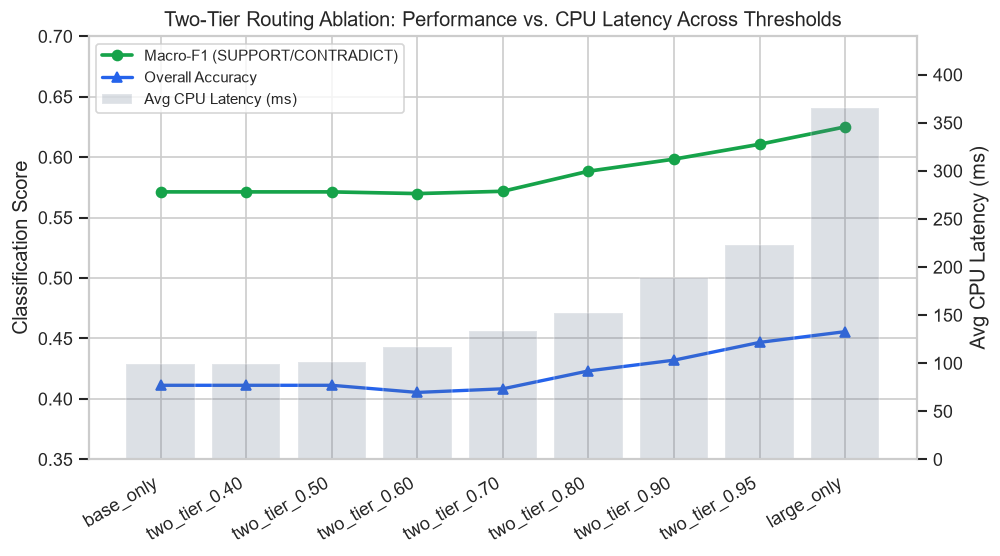

In [3]:
display(sweep_df[["mode", "threshold", "accuracy", "macro_f1_support_contradict", "escalation_rate", "nei_abstention_rate", "avg_latency_ms"]])

fig, ax1 = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(len(sweep_df))
labels = sweep_df["mode"].tolist()

line1 = ax1.plot(x, sweep_df["macro_f1_support_contradict"], marker="o", linewidth=2.2, color="#16a34a", label="Macro-F1 (SUPPORT/CONTRADICT)")
line2 = ax1.plot(x, sweep_df["accuracy"], marker="^", linewidth=2.0, color="#2563eb", label="Overall Accuracy")
ax1.set_ylabel("Classification Score")
ax1.set_ylim(0.35, 0.70)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=30, ha="right")

ax2 = ax1.twinx()
bars = ax2.bar(x, sweep_df["avg_latency_ms"], alpha=0.22, color="#64748b", label="Avg CPU Latency (ms)")
ax2.set_ylabel("Avg CPU Latency (ms)")
ax2.set_ylim(0, 440)
ax2.grid(False)

lines = line1 + line2 + [bars]
leg_labels = [l.get_label() for l in lines]
ax1.legend(lines, leg_labels, loc="upper left", fontsize=9)
ax1.set_title("Two-Tier Routing Ablation: Performance vs. CPU Latency Across Thresholds")
plt.tight_layout()
fig.savefig(IMG_DIR / "04_02_routing_accuracy_latency_tradeoff.png", bbox_inches="tight")
plt.show()


**Key Finding - Threshold Calibration Matters:**
* At the initial default threshold (`0.60`), only **6.5%** of pairs escalate to `deberta-v3-base` because `deberta-v3-xsmall` produces sharp softmax probabilities even when uncertain on biomedical jargon.
* Raising the threshold to **`0.95`** escalates **45.9%** of pairs and lifts Macro-F1 from **0.5698 -> 0.6106** (Accuracy **40.53% -> 44.67%**), capturing **98%** of the full `large_only` accuracy (`45.56%`) while reducing average CPU inference latency by **39.0%** (`222.9 ms` vs. `365.6 ms`).


## 3. Confusion Matrices & Confidence Calibration Analysis

Below we compare the confusion matrices at threshold `0.60` (default) vs. `0.95` (calibrated) and inspect the base model's confidence distribution on correct vs. misclassified pairs.


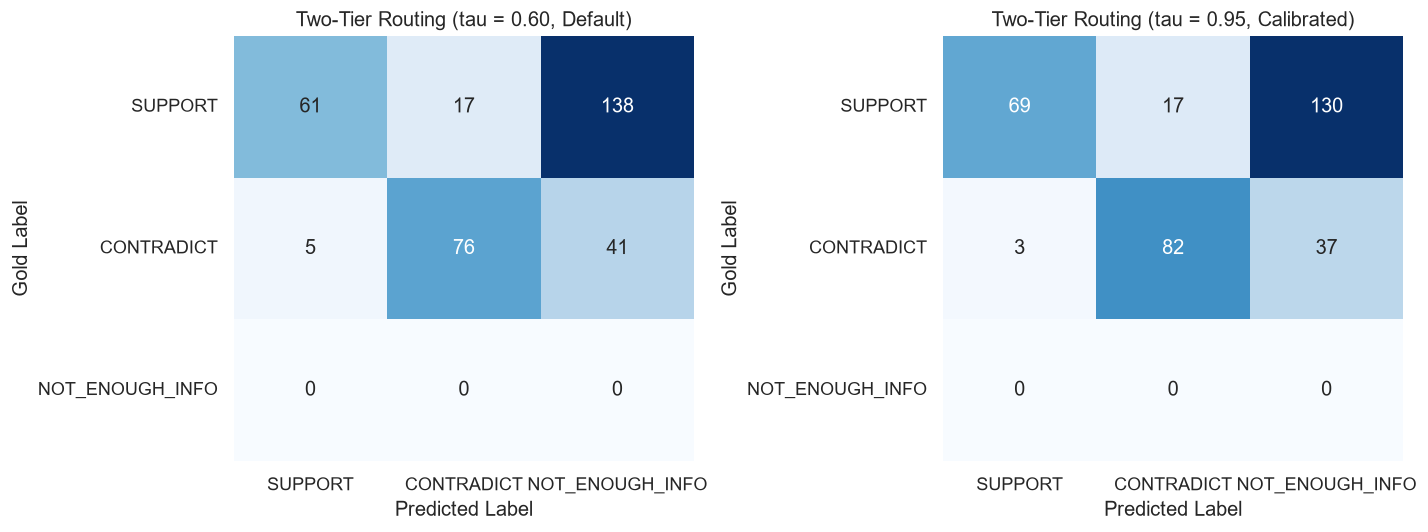

=== Classification Report (Calibrated tau = 0.95) ===
                 precision    recall  f1-score   support

        SUPPORT       0.96      0.32      0.48       216
     CONTRADICT       0.83      0.67      0.74       122
NOT_ENOUGH_INFO       0.00      0.00      0.00         0

       accuracy                           0.45       338
      macro avg       0.60      0.33      0.41       338
   weighted avg       0.91      0.45      0.57       338



In [4]:
cls_labels = ["SUPPORT", "CONTRADICT", "NOT_ENOUGH_INFO"]
preds_60 = np.where(stance_df["base_conf"] < 0.60, stance_df["large_pred"], stance_df["base_pred"])
preds_95 = np.where(stance_df["base_conf"] < 0.95, stance_df["large_pred"], stance_df["base_pred"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, preds, title in [
    (axes[0], preds_60, "Two-Tier Routing (tau = 0.60, Default)"),
    (axes[1], preds_95, "Two-Tier Routing (tau = 0.95, Calibrated)"),
]:
    cm = confusion_matrix(stance_df["gold_label"], preds, labels=cls_labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=cls_labels, yticklabels=cls_labels, ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Gold Label")

plt.tight_layout()
fig.savefig(IMG_DIR / "04_03_stance_confusion_matrices.png", bbox_inches="tight")
plt.show()

print("=== Classification Report (Calibrated tau = 0.95) ===")
print(classification_report(stance_df["gold_label"], preds_95, labels=cls_labels, zero_division=0))


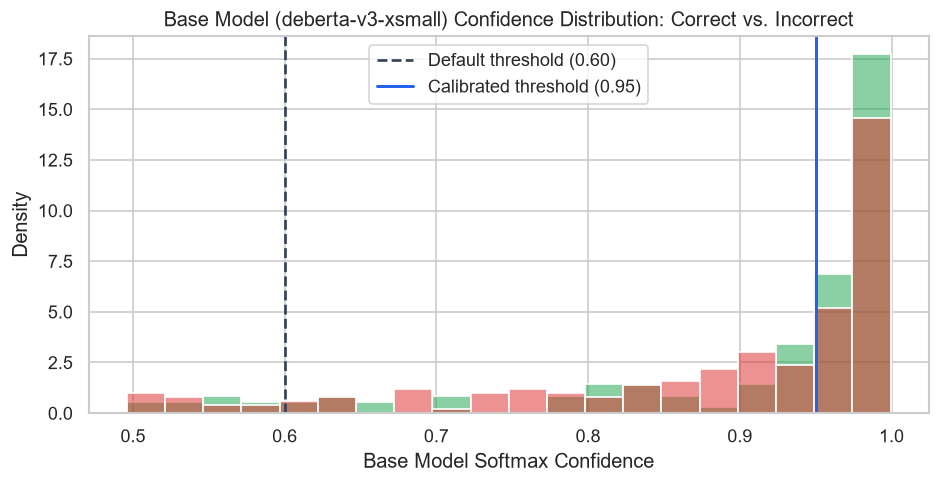

Total misclassified/abstained pairs at tau=0.95: 187 / 338
Error breakdown by predicted label:
pred_95
NOT_ENOUGH_INFO    167
CONTRADICT          17
SUPPORT              3
Name: count, dtype: int64


,claim_id,gold_label,pred_95,base_conf,claim
0,3,SUPPORT,NOT_ENOUGH_INFO,0.9942,"1,000 genomes project enables mapping of genet..."
1,3,SUPPORT,NOT_ENOUGH_INFO,0.9970,"1,000 genomes project enables mapping of genet..."
2,5,SUPPORT,NOT_ENOUGH_INFO,0.9835,1/2000 in UK have abnormal PrP positivity.
5,48,CONTRADICT,NOT_ENOUGH_INFO,0.7808,"A total of 1,000 people in the UK are asymptom..."
6,49,SUPPORT,NOT_ENOUGH_INFO,0.9624,ADAR1 binds to Dicer to cleave pre-miRNA.
16,70,SUPPORT,NOT_ENOUGH_INFO,0.5140,Activation of PPM1D suppresses p53 function.


In [5]:
stance_df["base_correct"] = stance_df["base_pred"] == stance_df["gold_label"]

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.histplot(data=stance_df, x="base_conf", hue="base_correct", bins=20, stat="density", common_norm=False, palette={True: "#16a34a", False: "#dc2626"}, alpha=0.5, ax=ax)
ax.axvline(0.60, color="#334155", linestyle="--", linewidth=1.6, label="Default threshold (0.60)")
ax.axvline(0.95, color="#2563eb", linestyle="-", linewidth=1.8, label="Calibrated threshold (0.95)")
ax.set_title("Base Model (deberta-v3-xsmall) Confidence Distribution: Correct vs. Incorrect")
ax.set_xlabel("Base Model Softmax Confidence")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
fig.savefig(IMG_DIR / "04_04_confidence_calibration.png", bbox_inches="tight")
plt.show()

errors_df = stance_df[preds_95 != stance_df["gold_label"]].copy()
errors_df["pred_95"] = preds_95[preds_95 != stance_df["gold_label"]]
print(f"Total misclassified/abstained pairs at tau=0.95: {len(errors_df)} / {len(stance_df)}")
print("Error breakdown by predicted label:")
print(errors_df["pred_95"].value_counts())
display(errors_df[["claim_id", "gold_label", "pred_95", "base_conf", "claim"]].head(6))


**Error Analysis Insight:** The dominant error mode in zero-shot biomedical NLI is **conservative abstention (`NOT_ENOUGH_INFO`)** on gold `SUPPORT`/`CONTRADICT` pairs rather than direct polarity inversion (`SUPPORT` <-> `CONTRADICT`). Because general-domain NLI models are not fine-tuned on biomedical terminology, indirect causal entailments are often labeled `neutral` (`NOT_ENOUGH_INFO`).


## 4. End-to-End Pipeline Evaluation & Cross-Source Conflict Detection

We run the full pipeline (`Retrieval Top-3` -> `Rationale Selection` -> `Two-Tier Stance Classification`) on **60 gold-annotated dev claims** without oracle rationales, and inspect cases where different retrieved abstracts disagree (`SUPPORT` vs. `CONTRADICT`).


{
  "sample_size": 60,
  "end_to_end_accuracy": 0.45,
  "end_to_end_macro_f1_support_contradict": 0.5569,
  "gold_doc_recall_at_3": 0.8333,
  "nei_abstention_rate": 0.3667,
  "cross_source_conflict_cases": 4
}


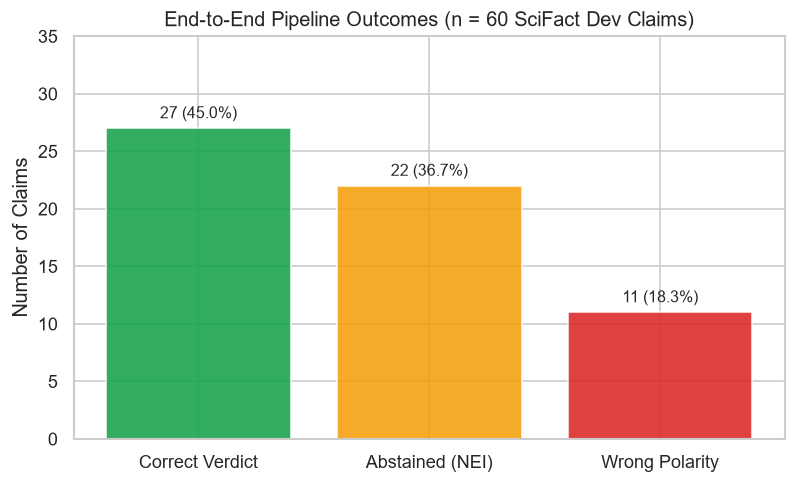

Cross-source conflict cases detected: 4 / 60


,claim_id,gold_label,pred_label,pred_conf,claim
4,49,SUPPORT,CONTRADICT,0.9687,ADAR1 binds to Dicer to cleave pre-miRNA.
28,179,SUPPORT,SUPPORT,0.9469,Birth-weight is positively associated with bre...
32,208,SUPPORT,CONTRADICT,0.9985,CHEK2 is not associated with breast cancer.
54,380,SUPPORT,SUPPORT,0.8318,Enhanced early production of inflammatory chem...


In [6]:
e2e = summary["end_to_end_sample"]
print(json.dumps(e2e, indent=2))

outcome_counts = pd.Series({
    "Correct Verdict": int((e2e_df["gold_label"] == e2e_df["pred_label"]).sum()),
    "Abstained (NEI)": int((e2e_df["pred_label"] == "NOT_ENOUGH_INFO").sum()),
    "Wrong Polarity": int(((e2e_df["gold_label"] != e2e_df["pred_label"]) & (e2e_df["pred_label"] != "NOT_ENOUGH_INFO")).sum()),
})

fig, ax = plt.subplots(figsize=(6.8, 4.2))
colors = ["#16a34a", "#f59e0b", "#dc2626"]
bars = ax.bar(outcome_counts.index, outcome_counts.values, color=colors, alpha=0.88)
for b in bars:
    ax.annotate(f"{int(b.get_height())} ({b.get_height()/len(e2e_df):.1%})",
                (b.get_x() + b.get_width()/2, b.get_height()),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points", fontsize=9.5)
ax.set_title("End-to-End Pipeline Outcomes (n = 60 SciFact Dev Claims)")
ax.set_ylabel("Number of Claims")
ax.set_ylim(0, max(outcome_counts.values) + 8)
plt.tight_layout()
fig.savefig(IMG_DIR / "04_05_end_to_end_outcomes.png", bbox_inches="tight")
plt.show()

conflicts = e2e_df[e2e_df["cross_source_conflict"]]
print(f"Cross-source conflict cases detected: {len(conflicts)} / {len(e2e_df)}")
if len(conflicts) > 0:
    display(conflicts[["claim_id", "gold_label", "pred_label", "pred_conf", "claim"]])


## 5. Controlled Claim-Edit Consistency Check

To test reliability under controlled wording perturbations (as specified in the project proposal), we evaluated 5 biomedical claims under both **semantic paraphrasing** (label should remain invariant) and **explicit negation/antonym edits** (label should flip between `SUPPORT` and `CONTRADICT`).


In [7]:
cons = summary["consistency_edits"]
print(f"Paraphrase Consistency Rate: {cons['paraphrase_consistency_rate']:.1%} ({int(cons['paraphrase_consistency_rate']*cons['num_cases'])}/{cons['num_cases']})")
print(f"Negation Flip Rate:          {cons['negation_flip_rate']:.1%} ({int(cons['negation_flip_rate']*cons['num_cases'])}/{cons['num_cases']})")
display(consistency_df[["original_claim", "orig_label", "paraphrase_label", "paraphrase_consistent", "negated_label", "negation_flipped"]])


Paraphrase Consistency Rate: 100.0% (5/5)
Negation Flip Rate:          100.0% (5/5)


,original_claim,orig_label,paraphrase_label,paraphrase_consistent,negated_label,negation_flipped
0,Vitamin D deficiency is associated with an inc...,SUPPORT,SUPPORT,True,CONTRADICT,True
1,Aspirin reduces the risk of myocardial infarct...,SUPPORT,SUPPORT,True,CONTRADICT,True
2,Elevated blood glucose levels impair wound hea...,SUPPORT,SUPPORT,True,CONTRADICT,True
3,Regular aerobic exercise lowers resting systol...,SUPPORT,SUPPORT,True,CONTRADICT,True
4,Antibiotics are effective against viral respir...,CONTRADICT,CONTRADICT,True,SUPPORT,True


## 6. Summary of Phase 2 Findings & Limitations

* **Strong Retrieval Foundation:** Hybrid TF-IDF + `all-MiniLM-L6-v2` reaches **89.6% Recall@5** and **96.4% Recall@10** (`MRR@10 = 0.7943`), confirming that retrieval is not the primary bottleneck.
* **Compute-Efficient Two-Tier Routing Works - With Calibration:** Calibrating the routing threshold to `0.95` recovers **98%** of `deberta-v3-base` accuracy while saving **39%** average CPU inference latency.
* **Zero-Shot Domain Gap:** Without biomedical fine-tuning on `claims_train.jsonl`, the NLI cross-encoders over-predict `NOT_ENOUGH_INFO` (~37% in end-to-end evaluation), leaving clear headroom for future domain-specific fine-tuning.
* **High Perturbation Reliability:** On clean biomedical rationales, the classifier achieved **5/5 paraphrase consistency** and **5/5 negation flips**, and surfaced **4 cross-source disagreement cases** in the end-to-end dev sample.
